# Activité Pratique N°5 — Agentic AI et MCP
## Partie B.1 : Bases de LangGraph

**IA Générative Multi Modale — 5IAD G1, EMSI** · Étudiant : BENHAYOUN SADAFI Mohamed

**Objectif :** mettre en œuvre les concepts de base de LangGraph : **état** (State), **nœuds** (Nodes), **arêtes** (Edges), arêtes **conditionnelles**, **boucles**, **reducers**, agent avec **tools**, **mémoire**, **streaming** et **interruption humaine**.

| Concept | Rôle |
|---|---|
| **State** | Structure de données partagée (un `TypedDict`) qui circule dans le graphe |
| **Node** | Fonction Python qui reçoit l'état et renvoie une mise à jour partielle |
| **Edge** | Lien fixe entre deux nœuds (`START` → nœud → `END`) |
| **Conditional edge** | Fonction de routage qui choisit le nœud suivant selon l'état |
| **Reducer** | Règle de fusion d'un champ (ex. `add_messages` ajoute au lieu de remplacer) |
| **Checkpointer** | Sauvegarde l'état après chaque étape : mémoire, reprise après interruption |

In [1]:
import os
from typing import Annotated, Literal, TypedDict

from dotenv import load_dotenv
from IPython.display import Image, Markdown, display
from langgraph.graph import END, START, StateGraph

load_dotenv(override=True)


def afficher_graphe(graphe):
    """Affiche le graphe en image (service mermaid.ink) ou, à défaut, en texte Mermaid."""
    try:
        display(Image(graphe.get_graph().draw_mermaid_png()))
    except Exception:
        print(graphe.get_graph().draw_mermaid())

## 1. Graphe minimal : un état, un nœud

Un nœud renvoie uniquement les champs qu'il modifie ; LangGraph fusionne cette mise à jour dans l'état.

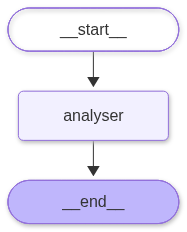

{'texte': 'BONJOUR LANGGRAPH', 'longueur': 17}

In [2]:
class EtatTexte(TypedDict):
    texte: str
    longueur: int


def analyser(etat: EtatTexte) -> dict:
    return {"texte": etat["texte"].upper(), "longueur": len(etat["texte"])}


workflow = StateGraph(EtatTexte)
workflow.add_node("analyser", analyser)
workflow.add_edge(START, "analyser")
workflow.add_edge("analyser", END)
graphe_minimal = workflow.compile()

afficher_graphe(graphe_minimal)
graphe_minimal.invoke({"texte": "bonjour langgraph"})

## 2. Plusieurs nœuds en séquence

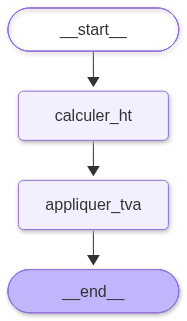

{'produit': 'Imprimante PX-200',
 'quantite': 3,
 'prix_unitaire': 1490.0,
 'total_ht': 4470.0,
 'total_ttc': 5364.0}

In [3]:
class EtatCommande(TypedDict):
    produit: str
    quantite: int
    prix_unitaire: float
    total_ht: float
    total_ttc: float


def calculer_ht(etat: EtatCommande) -> dict:
    return {"total_ht": etat["quantite"] * etat["prix_unitaire"]}


def appliquer_tva(etat: EtatCommande) -> dict:
    return {"total_ttc": round(etat["total_ht"] * 1.20, 2)}


workflow = StateGraph(EtatCommande)
workflow.add_node("calculer_ht", calculer_ht)
workflow.add_node("appliquer_tva", appliquer_tva)
workflow.add_edge(START, "calculer_ht")
workflow.add_edge("calculer_ht", "appliquer_tva")
workflow.add_edge("appliquer_tva", END)
graphe_commande = workflow.compile()

afficher_graphe(graphe_commande)
graphe_commande.invoke({"produit": "Imprimante PX-200", "quantite": 3, "prix_unitaire": 1490.0})

## 3. Arêtes conditionnelles

La fonction de routage lit l'état et renvoie le **nom de la branche** à suivre.

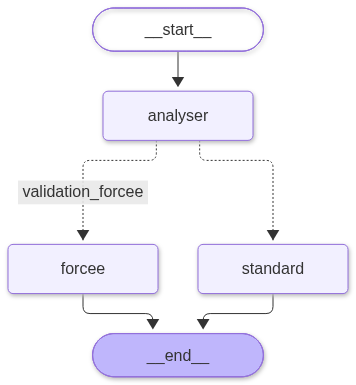

Demande de Mohamed envoyée au traitement RH standard
Demande de Yassine envoyée à la validation RH forcée


In [4]:
class EtatEmploye(TypedDict):
    nom: str
    age: int
    salaire: float
    decision: Literal["standard", "validation_forcee"]
    resultat: str


def analyser_employe(etat: EtatEmploye) -> dict:
    standard = etat["age"] <= 30 and etat["salaire"] <= 40000
    return {"decision": "standard" if standard else "validation_forcee"}


def traitement_standard(etat: EtatEmploye) -> dict:
    return {"resultat": f"Demande de {etat['nom']} envoyée au traitement RH standard"}


def validation_forcee(etat: EtatEmploye) -> dict:
    return {"resultat": f"Demande de {etat['nom']} envoyée à la validation RH forcée"}


def router(etat: EtatEmploye) -> str:
    return etat["decision"]


workflow = StateGraph(EtatEmploye)
workflow.add_node("analyser", analyser_employe)
workflow.add_node("standard", traitement_standard)
workflow.add_node("forcee", validation_forcee)
workflow.add_edge(START, "analyser")
workflow.add_conditional_edges("analyser", router, {"standard": "standard", "validation_forcee": "forcee"})
workflow.add_edge("standard", END)
workflow.add_edge("forcee", END)
graphe_rh = workflow.compile()

afficher_graphe(graphe_rh)
print(graphe_rh.invoke({"nom": "Mohamed", "age": 23, "salaire": 20000})["resultat"])
print(graphe_rh.invoke({"nom": "Yassine", "age": 55, "salaire": 65000})["resultat"])

## 4. Boucle

Une arête qui revient vers un nœud précédent crée une boucle ; la condition de sortie est dans la fonction de routage.

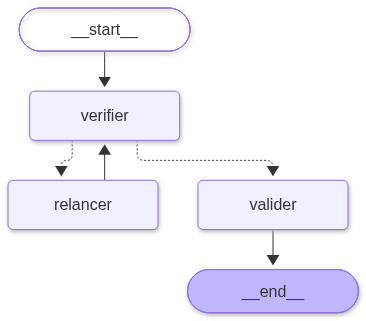

Vérification du dossier de Salma : incomplet (3 document(s) manquant(s))
  -> relance n°1 envoyée, l'employé fournit un document
Vérification du dossier de Salma : incomplet (2 document(s) manquant(s))
  -> relance n°2 envoyée, l'employé fournit un document
Vérification du dossier de Salma : incomplet (1 document(s) manquant(s))
  -> relance n°3 envoyée, l'employé fournit un document
Vérification du dossier de Salma : complet (0 document(s) manquant(s))
Dossier de Salma validé après 3 relance(s)


{'nom': 'Salma', 'documents_manquants': 0, 'relances': 3, 'statut': 'valide'}

In [5]:
class EtatDossier(TypedDict):
    nom: str
    documents_manquants: int
    relances: int
    statut: Literal["incomplet", "complet", "valide"]


def verifier_dossier(etat: EtatDossier) -> dict:
    statut = "incomplet" if etat["documents_manquants"] > 0 else "complet"
    print(f"Vérification du dossier de {etat['nom']} : {statut} ({etat['documents_manquants']} document(s) manquant(s))")
    return {"statut": statut}


def relancer_employe(etat: EtatDossier) -> dict:
    print(f"  -> relance n°{etat['relances'] + 1} envoyée, l'employé fournit un document")
    return {"relances": etat["relances"] + 1, "documents_manquants": etat["documents_manquants"] - 1}


def valider_dossier(etat: EtatDossier) -> dict:
    print(f"Dossier de {etat['nom']} validé après {etat['relances']} relance(s)")
    return {"statut": "valide"}


def router_dossier(etat: EtatDossier) -> Literal["relancer", "valider"]:
    return "relancer" if etat["statut"] == "incomplet" else "valider"


workflow = StateGraph(EtatDossier)
workflow.add_node("verifier", verifier_dossier)
workflow.add_node("relancer", relancer_employe)
workflow.add_node("valider", valider_dossier)
workflow.add_edge(START, "verifier")
workflow.add_conditional_edges("verifier", router_dossier)
workflow.add_edge("relancer", "verifier")
workflow.add_edge("valider", END)
graphe_dossier = workflow.compile()

afficher_graphe(graphe_dossier)
graphe_dossier.invoke({"nom": "Salma", "documents_manquants": 3, "relances": 0})

## 5. Reducers : comment un champ est mis à jour

Sans reducer, la valeur renvoyée par un nœud **remplace** l'ancienne. Avec `Annotated[list, operator.add]` ou `add_messages`, elle est **ajoutée**.
Les deux nœuds ci-dessous s'exécutent **en parallèle** (même nœud de départ) : leurs résultats sont fusionnés par le reducer.

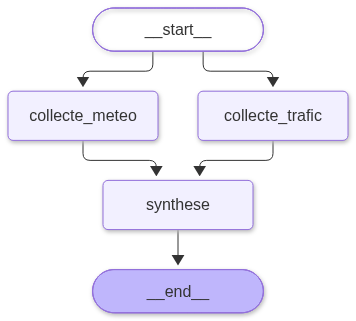

{'journal': ['démarrage',
  'météo collectée',
  'trafic collecté',
  'synthèse de 3 sources']}

In [6]:
import operator


class EtatJournal(TypedDict):
    journal: Annotated[list[str], operator.add]


workflow = StateGraph(EtatJournal)
workflow.add_node("collecte_meteo", lambda etat: {"journal": ["météo collectée"]})
workflow.add_node("collecte_trafic", lambda etat: {"journal": ["trafic collecté"]})
workflow.add_node("synthese", lambda etat: {"journal": [f"synthèse de {len(etat['journal'])} sources"]})
workflow.add_edge(START, "collecte_meteo")
workflow.add_edge(START, "collecte_trafic")
workflow.add_edge(["collecte_meteo", "collecte_trafic"], "synthese")
workflow.add_edge("synthese", END)
graphe_parallele = workflow.compile()

afficher_graphe(graphe_parallele)
graphe_parallele.invoke({"journal": ["démarrage"]})

## 6. Un nœud qui appelle le LLM

L'état contient une liste de messages avec le reducer `add_messages` (c'est ce que fait `MessagesState`).

In [7]:
from langchain.messages import AIMessage, HumanMessage, SystemMessage
from langchain_openai import AzureChatOpenAI
from langgraph.graph import MessagesState

llm = AzureChatOpenAI(
    azure_endpoint=os.getenv("AZURE_OPENAI_ENDPOINT"),
    api_key=os.getenv("AZURE_OPENAI_API_KEY"),
    api_version=os.getenv("AZURE_OPENAI_API_VERSION"),
    azure_deployment=os.getenv("AZURE_OPENAI_DEPLOYMENT"),
    temperature=0,
    timeout=30,
)


def chatbot(etat: MessagesState) -> dict:
    systeme = SystemMessage("Tu es un assistant concis. Réponds en français en 2 phrases maximum.")
    return {"messages": [llm.invoke([systeme] + etat["messages"])]}


workflow = StateGraph(MessagesState)
workflow.add_node("chatbot", chatbot)
workflow.add_edge(START, "chatbot")
workflow.add_edge("chatbot", END)
graphe_chatbot = workflow.compile()

resultat = graphe_chatbot.invoke({"messages": [HumanMessage("Quelle différence entre LangChain et LangGraph ?")]})
for message in resultat["messages"]:
    message.pretty_print()

================================ Human Message =================================

Quelle différence entre LangChain et LangGraph ?
================================== Ai Message ==================================

LangChain est une bibliothèque pour construire des applications basées sur des modèles de langage en orchestrant des composants comme les LLMs, les chaînes et les agents. LangGraph, quant à lui, est une plateforme visuelle permettant de créer et gérer des workflows d'IA via une interface graphique, facilitant l'intégration de modèles et de données.


## 7. Agent ReAct construit à la main : LLM + ToolNode + boucle

- Le nœud `assistant` appelle le LLM avec les tools liés (`bind_tools`)
- Si le LLM demande des tools, on passe au nœud `tools` (`ToolNode`) puis on **revient** à l'assistant
- Sinon, fin du graphe

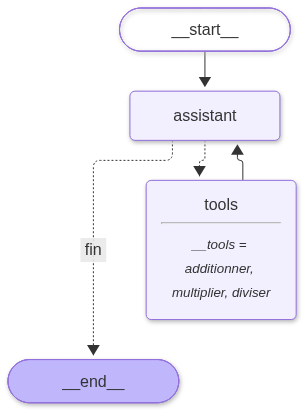

In [8]:
from langchain.tools import tool
from langgraph.prebuilt import ToolNode


@tool
def additionner(a: float, b: float) -> float:
    """Additionne deux nombres a et b."""
    print(f"  [tool] additionner({a}, {b})")
    return a + b


@tool
def multiplier(a: float, b: float) -> float:
    """Multiplie deux nombres a et b."""
    print(f"  [tool] multiplier({a}, {b})")
    return a * b


@tool
def diviser(a: float, b: float) -> float:
    """Divise a par b."""
    print(f"  [tool] diviser({a}, {b})")
    return a / b


outils = [additionner, multiplier, diviser]
llm_avec_outils = llm.bind_tools(outils)


def assistant(etat: MessagesState) -> dict:
    return {"messages": [llm_avec_outils.invoke(etat["messages"])]}


def continuer(etat: MessagesState) -> Literal["tools", "fin"]:
    return "tools" if etat["messages"][-1].tool_calls else "fin"


workflow = StateGraph(MessagesState)
workflow.add_node("assistant", assistant)
workflow.add_node("tools", ToolNode(outils))
workflow.add_edge(START, "assistant")
workflow.add_conditional_edges("assistant", continuer, {"tools": "tools", "fin": END})
workflow.add_edge("tools", "assistant")
agent_calcul = workflow.compile()

afficher_graphe(agent_calcul)

In [9]:
resultat = agent_calcul.invoke({"messages": [HumanMessage("Ajoute 5 à 80, multiplie le résultat par 23, puis divise par 5.")]})
print(resultat["messages"][-1].content)

  [tool] additionner(80.0, 5.0)
  [tool] multiplier(85.0, 23.0)
  [tool] diviser(1955.0, 5.0)


J'ai ajouté 5 à 80 pour obtenir 85, puis multiplié ce résultat par 23 pour obtenir 1955, et enfin divisé par 5 pour obtenir 391. Le résultat final est donc 391.


### Streaming : suivre l'exécution étape par étape

`stream_mode="updates"` renvoie la mise à jour produite par chaque nœud, au fur et à mesure.

In [10]:
for etape in agent_calcul.stream({"messages": [HumanMessage("Combien font (12 + 30) x 4 ?")]}, stream_mode="updates"):
    for noeud, mise_a_jour in etape.items():
        dernier = mise_a_jour["messages"][-1]
        contenu = dernier.tool_calls if getattr(dernier, "tool_calls", None) else dernier.content
        print(f"[{noeud}] {contenu}")

[assistant] [{'name': 'additionner', 'args': {'a': 12, 'b': 30}, 'id': 'call_xMAGvsOhtM82ltEJiOrYtckx', 'type': 'tool_call'}, {'name': 'multiplier', 'args': {'a': 42, 'b': 4}, 'id': 'call_HO74XxOThHbJqMOxnu02p0hD', 'type': 'tool_call'}]
  [tool] additionner(12.0, 30.0)
  [tool] multiplier(42.0, 4.0)
[tools] 168.0


[assistant] (12 + 30) fait 42, et 42 multiplié par 4 fait 168. Donc, (12 + 30) x 4 = 168.


## 8. Mémoire : checkpointer et thread_id

En compilant avec un `checkpointer`, l'état est sauvegardé par `thread_id` : la conversation continue d'un appel à l'autre.

In [11]:
from langgraph.checkpoint.memory import InMemorySaver

agent_memoire = workflow.compile(checkpointer=InMemorySaver())
config = {"configurable": {"thread_id": "1"}}

r = agent_memoire.invoke({"messages": [HumanMessage("Je m'appelle Mohamed. Calcule 7 x 6.")]}, config=config)
print(r["messages"][-1].content)
r = agent_memoire.invoke({"messages": [HumanMessage("Comment je m'appelle, et ajoute 8 au résultat précédent.")]}, config=config)
print(r["messages"][-1].content)

  [tool] multiplier(7.0, 6.0)


Bonjour Mohamed ! Le résultat de 7 multiplié par 6 est 42.


  [tool] additionner(42.0, 8.0)


Tu t'appelles Mohamed. En ajoutant 8 au résultat précédent (42), on obtient 50.


In [12]:
# Historique des checkpoints du thread : un état sauvegardé après chaque super-étape
historique = list(agent_memoire.get_state_history(config))
print(f"{len(historique)} checkpoints pour le thread 1")
for snapshot in historique[:5]:
    print(f"  prochain nœud : {snapshot.next} | {len(snapshot.values['messages'])} messages")

10 checkpoints pour le thread 1
  prochain nœud : () | 8 messages
  prochain nœud : ('assistant',) | 7 messages
  prochain nœud : ('tools',) | 6 messages
  prochain nœud : ('assistant',) | 5 messages
  prochain nœud : ('__start__',) | 4 messages


## 9. Human in the loop avec `interrupt`

`interrupt()` met le graphe en pause et renvoie une valeur à l'humain ; `Command(resume=...)` reprend l'exécution avec sa réponse.
Exemple : un assistant rédige un e-mail, l'humain l'approuve ou demande une correction.

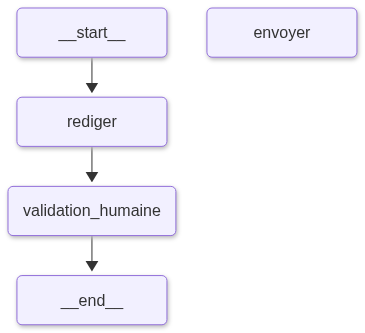

In [13]:
from langgraph.types import Command, interrupt


class EtatEmail(TypedDict, total=False):
    destinataire: str
    sujet: str
    brouillon: str
    retour_humain: str
    envoye: bool


def rediger(etat: EtatEmail) -> dict:
    consigne = f"Rédige un e-mail court et poli à {etat['destinataire']} sur le sujet : {etat['sujet']}."
    if etat.get("retour_humain"):
        consigne += f"\nVersion précédente :\n{etat['brouillon']}\nCorrection demandée : {etat['retour_humain']}"
    return {"brouillon": llm.invoke(consigne).content}


def validation_humaine(etat: EtatEmail) -> dict:
    reponse = interrupt({"brouillon": etat["brouillon"], "question": "Approuver (ok) ou indiquer une correction ?"})
    if reponse == "ok":
        return {"retour_humain": "", "envoye": True}
    return {"retour_humain": reponse, "envoye": False}


def envoyer(etat: EtatEmail) -> dict:
    print(f"E-mail envoyé à {etat['destinataire']}")
    return {}


workflow = StateGraph(EtatEmail)
workflow.add_node("rediger", rediger)
workflow.add_node("validation_humaine", validation_humaine)
workflow.add_node("envoyer", envoyer)
workflow.add_edge(START, "rediger")
workflow.add_edge("rediger", "validation_humaine")
workflow.add_conditional_edges("validation_humaine", lambda e: "envoyer" if e["envoye"] else "rediger")
workflow.add_edge("envoyer", END)
graphe_email = workflow.compile(checkpointer=InMemorySaver())

afficher_graphe(graphe_email)

In [14]:
config_email = {"configurable": {"thread_id": "email-1"}}
etat = graphe_email.invoke({"destinataire": "Pr. Youssfi", "sujet": "rendu de l'activité pratique N°5"}, config=config_email)
print("PAUSE — brouillon proposé :\n")
print(etat["__interrupt__"][0].value["brouillon"])

PAUSE — brouillon proposé :

Objet : Rendu de l'activité pratique N°5

Bonjour Professeur Youssfi,

Je vous écris pour vous informer que j’ai terminé l’activité pratique N°5 et que je suis prêt(e) à vous la soumettre. Pourriez-vous m’indiquer la procédure à suivre pour le rendu ?

Je vous remercie par avance pour votre aide.

Cordialement,  
[Votre prénom et nom]


In [15]:
# L'humain demande une correction : le graphe repart vers « rediger » puis s'arrête à nouveau
etat = graphe_email.invoke(Command(resume="Plus court, 3 phrases maximum, et mentionne le lien GitHub."), config=config_email)
print("PAUSE — nouveau brouillon :\n")
print(etat["__interrupt__"][0].value["brouillon"])

PAUSE — nouveau brouillon :

Objet : Rendu de l’activité pratique N°5

Bonjour Professeur Youssfi,

L’activité pratique N°5 est terminée et disponible sur mon GitHub (lien ci-dessous). Pourriez-vous m’indiquer la procédure pour le rendu ?  
Merci d’avance.

Cordialement,  
[Votre prénom et nom]


In [16]:
# L'humain approuve : envoi et fin du graphe
etat = graphe_email.invoke(Command(resume="ok"), config=config_email)
print("Envoyé :", etat["envoye"])

E-mail envoyé à Pr. Youssfi
Envoyé : True


**Bilan :** LangGraph rend explicite ce que `create_agent` fait en interne (boucle LLM ↔ tools) et permet de construire des workflows sur mesure : routage, boucles, parallélisme, mémoire persistante et validation humaine. La partie B.2 applique ces concepts à un **chatbot Agentic RAG**.